# 05: Economics, uncertainty and sizing

*Phase 2.5 of the extension. The reasoning and the findings are explained in `docs/report.md`, section 2.5.*

Notebook 04 showed that the final report design (14 dishes, no store) meets about a third of the load. This notebook asks the questions a decision-maker would ask next:

1. How much does the answer move with the weather year, fuel price, costs and the unstated assumptions (meal hours, store losses)?
2. What do 14 dishes cost once the retrofit the final report left out and a store are included, and does the project still pay back?
3. Which combination of dish count and store size is best, and how robust is that choice?
4. Which inputs matter most?

The base case differs from the final report in three declared ways: the 30 % kitchen retrofit is **included** in the capital cost, the store is costed at a **placeholder** INR 1,000 per MJ (no quotation exists), and the LPG price is held constant (as in the final report) unless an escalation is drawn. All input ranges and the reason for each are in `configs/uncertainty.yaml`.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import TwoSlopeNorm

from en630.config import load_config
from en630.plotting import DIVERGING, INK, SEQ_BLUE, SERIES, SURFACE, apply_theme, save
from en630.uncertainty import (
    Evaluator, load_distributions, modes, monte_carlo, pareto_front, sizing_sweep, sobol_indices,
)
from en630.weather import IIT_BOMBAY, read_multiyear_csv, read_tmy_csv

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*dayofyear.*")
apply_theme()
DATA, FIG = Path("../data"), Path("../docs/figures")
FIG.mkdir(parents=True, exist_ok=True)

cfg, dists = load_config(), load_distributions()
my = read_multiyear_csv(DATA / "pvgis_dni_2005_2023_iitb.csv.gz")
years = {y: g for y, g in my.groupby(my.index.year)}
tmy = read_tmy_csv(DATA / "pvgis_tmy_iitb.csv")[["dni", "temp_air"]]
ev = Evaluator(years, IIT_BOMBAY, cfg, dists)            # 19 real years
ev_tmy = Evaluator({"TMY": tmy}, IIT_BOMBAY, cfg, dists)  # the typical year used so far
base = modes(dists)
LAKH = 1e5
print(f"{len(years)} weather years; {len(dists['parameters'])} uncertain inputs")

19 weather years; 11 uncertain inputs


## 1: Year-to-year weather variability

The typical year hides how much a real year can differ. For the 14-dish field with a 1000 MJ store, the base-case inputs are held fixed and only the weather year changes.

,beam (kWh/m²),solar fraction,collected (MWh),NPV (lakh INR)
mean,2027.65,0.78,168.96,11.75
min,1876.34,0.74,153.81,6.02
max,2106.18,0.82,176.57,17.14


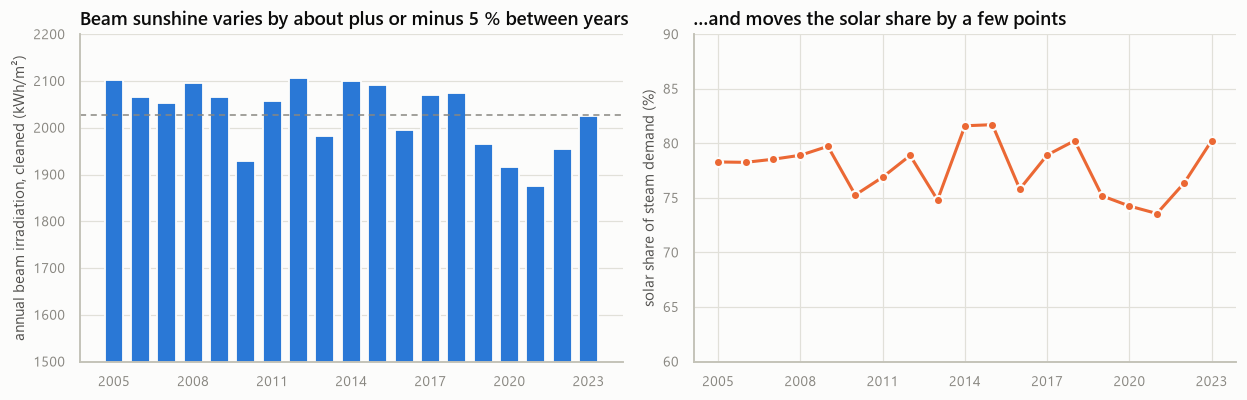

Useful heat from 14 dishes: median 172 MWh, P90 (exceeded in 9 years of 10) 159 MWh


In [2]:
rows = []
for y in years:
    r = ev.evaluate({**base, "weather_year": y}, 14, 1000.0)
    rows.append({"year": y, "beam (kWh/m²)": ev._wx[y]["dni"].sum() / 1000, "solar fraction": r["solar_fraction"],
                 "collected (MWh)": r["useful_collector_mwh"], "NPV (lakh INR)": r["npv_inr"] / LAKH})
yr = pd.DataFrame(rows).set_index("year")
display(yr.describe().loc[["mean", "min", "max"]].round(2))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
ax = axes[0]
ax.bar(yr.index, yr["beam (kWh/m²)"], color=SERIES[0], width=0.72, edgecolor=SURFACE, linewidth=1.2)
ax.axhline(yr["beam (kWh/m²)"].mean(), color=INK["muted"], linewidth=1, linestyle=(0, (4, 3)))
ax.set_ylim(1500, 2200)
ax.set_ylabel("annual beam irradiation, cleaned (kWh/m²)")
ax.set_title("Beam sunshine varies by about plus or minus 5 % between years")
ax.grid(axis="x", visible=False)
ax.set_xticks(range(2005, 2024, 3))
ax = axes[1]
ax.plot(yr.index, yr["solar fraction"] * 100, color=SERIES[1], marker="o", markersize=6, markeredgecolor=SURFACE, markeredgewidth=1.4)
ax.set_ylim(60, 90)
ax.set_ylabel("solar share of steam demand (%)")
ax.set_title("...and moves the solar share by a few points")
ax.set_xticks(range(2005, 2024, 3))
fig.tight_layout()
save(fig, FIG / "econ_year_variability.png")
plt.show()
p10 = yr["collected (MWh)"].quantile(0.10)
print(f"Useful heat from 14 dishes: median {yr['collected (MWh)'].median():.0f} MWh, P90 (exceeded in 9 years of 10) {p10:.0f} MWh")

## 2: The base case, three designs

Typical-year weather, inputs at their base values (including the retrofit and a store cost).

In [3]:
designs = {"Final report design: 14 dishes, no store": (14, 0.0), "14 dishes + 1000 MJ store": (14, 1000.0)}
rows = {}
for name, (n, s) in designs.items():
    r = ev_tmy.evaluate(base, n, s)
    rows[name] = {"capital (lakh INR)": r["capex_inr"] / LAKH, "solar fraction": r["solar_fraction"],
                  "cylinders displaced / yr": r["cylinders_displaced"], "NPV (lakh INR)": r["npv_inr"] / LAKH,
                  "simple payback (yr)": r["simple_payback_years"], "IRR (%)": 100 * ev_tmy.irr(base, n, s),
                  "solar heat cost (INR/MJ)": r["lcoh_inr_per_mj"], "LPG heat cost (INR/MJ)": r["lpg_inr_per_mj"]}
pd.DataFrame(rows).round(2)

,"Final report design: 14 dishes, no store",14 dishes + 1000 MJ store
capital (lakh INR),72.80,82.80
solar fraction,0.34,0.78
cylinders displaced / yr,454.36,1034.40
NPV (lakh INR),-36.52,11.42
simple payback (yr),11.91,5.95
IRR (%),0.11,12.32
solar heat cost (INR/MJ),6.11,3.05
LPG heat cost (INR/MJ),3.42,3.42


Without a store, the solar heat costs more than the LPG it replaces (INR/MJ column) and the NPV is negative: the field is idle in the evening, when most of the steam is needed. With a store the field pays back. The retrofit and the store cost are both inputs of this result, which is why they are included in the uncertainty analysis below.

## 3: Sizing: dishes and store together

Best NPV: 10 dishes, 750 MJ store -> NPV 29.9 lakh, solar share 72%, LCOH 2.38 INR/MJ


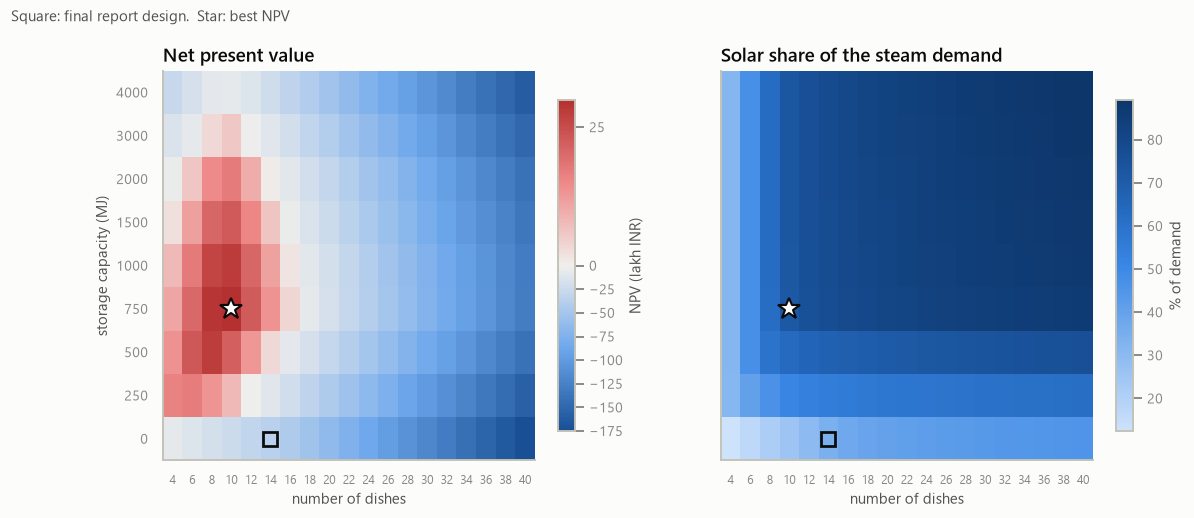

In [4]:
dishes = list(range(4, 41, 2))
stores = [0, 250, 500, 750, 1000, 1500, 2000, 3000, 4000]
sw = sizing_sweep(ev_tmy, base, dishes, stores)
npv = sw.pivot(index="storage_mj", columns="n_dishes", values="npv_inr") / LAKH
sf = sw.pivot(index="storage_mj", columns="n_dishes", values="solar_fraction") * 100
best = sw.loc[sw["npv_inr"].idxmax()]
print(f"Best NPV: {int(best.n_dishes)} dishes, {best.storage_mj:.0f} MJ store -> NPV {best.npv_inr / LAKH:.1f} lakh, solar share {best.solar_fraction:.0%}, "
      f"LCOH {best.lcoh_inr_per_mj:.2f} INR/MJ")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, tbl, cmap, norm, title, label in (
    (axes[0], npv, DIVERGING, TwoSlopeNorm(vmin=npv.to_numpy().min(), vcenter=0.0, vmax=npv.to_numpy().max()), "Net present value", "NPV (lakh INR)"),
    (axes[1], sf, SEQ_BLUE, None, "Solar share of the steam demand", "% of demand"),
):
    im = ax.imshow(tbl.to_numpy(), origin="lower", aspect="auto", cmap=cmap, norm=norm)
    ax.set_xticks(range(len(dishes)), dishes, fontsize=8)
    ax.set_yticks(range(len(stores)), stores)
    ax.set_xlabel("number of dishes")
    ax.set_title(title)
    ax.grid(False)
    fig.colorbar(im, ax=ax, label=label, shrink=0.85)
    ix, iy = dishes.index(14), stores.index(0)
    ax.plot(ix, iy, marker="s", markersize=9, markerfacecolor="none", markeredgecolor=INK["primary"], markeredgewidth=1.8)
    ax.plot(dishes.index(int(best.n_dishes)), stores.index(best.storage_mj), marker="*", markersize=15, markerfacecolor="white", markeredgecolor=INK["primary"], markeredgewidth=1.4)
axes[0].set_ylabel("storage capacity (MJ)")
fig.suptitle("Square: final report design.  Star: best NPV", x=0.01, y=1.0, ha="left", fontsize=10, color=INK["secondary"])
save(fig, FIG / "econ_sizing_heatmaps.png")
plt.show()

## 4: Cost against solar share: the Pareto front

Each point is a design; the front keeps those that no other design beats on both the levelised cost of heat (lower is better) and the solar share (higher is better). The dashed line is what the same heat costs from LPG.

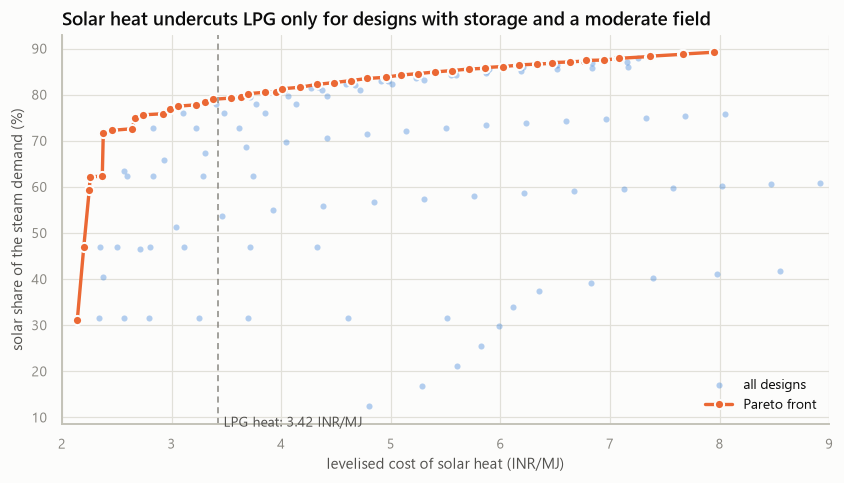

16 Pareto designs cost less than LPG; the largest solar share among them is 79%


,n_dishes,storage_mj,solar_fraction,lcoh_inr_per_mj,npv_inr
48,14,750,0.77,2.98,1352811.92
49,14,1000,0.78,3.05,1141601.56
50,14,1500,0.78,3.23,611464.46
57,16,750,0.78,3.31,367948.00
58,16,1000,0.79,3.37,158428.82


In [5]:
front = pareto_front(sw)
lpg = sw["lpg_inr_per_mj"].iloc[0]
fig, ax = plt.subplots(figsize=(9, 4.6))
ok = sw.replace([np.inf, -np.inf], np.nan).dropna(subset=["lcoh_inr_per_mj"])
ax.scatter(ok.lcoh_inr_per_mj, ok.solar_fraction * 100, s=16, color=SERIES[0], alpha=0.35, linewidths=0, label="all designs")
ax.plot(front.lcoh_inr_per_mj, front.solar_fraction * 100, color=SERIES[1], linewidth=2.2, marker="o", markersize=6, markeredgecolor=SURFACE, markeredgewidth=1.3, label="Pareto front")
ax.axvline(lpg, color=INK["muted"], linewidth=1, linestyle=(0, (4, 3)))
ax.text(lpg + 0.05, 8, f"LPG heat: {lpg:.2f} INR/MJ", fontsize=9, color=INK["secondary"])
ax.set_xlabel("levelised cost of solar heat (INR/MJ)")
ax.set_ylabel("solar share of the steam demand (%)")
ax.set_xlim(2, min(9, ok.lcoh_inr_per_mj.max()))
ax.legend(loc="lower right")
ax.set_title("Solar heat undercuts LPG only for designs with storage and a moderate field")
save(fig, FIG / "econ_pareto.png")
plt.show()
cheaper = front[front.lcoh_inr_per_mj < lpg]
print(f"{len(cheaper)} Pareto designs cost less than LPG; the largest solar share among them is {cheaper.solar_fraction.max():.0%}")
display(cheaper[["n_dishes", "storage_mj", "solar_fraction", "lcoh_inr_per_mj", "npv_inr"]].round(2).tail(5))

## 5: How robust is each design? Monte Carlo

All eleven inputs are drawn together (2000 samples, fixed seed) for three designs: the final report design (14 dishes, no store), the 14-dish design with a 1000 MJ store, and the best-NPV design from the sweep (found at the base inputs, so it is optimal for them, not for the uncertain case).

,NPV P10 (lakh),NPV P50 (lakh),NPV P90 (lakh),P(NPV < 0),solar share P50,LCOH P50 (INR/MJ),P(solar heat cheaper than LPG)
"the final report as built 14 dishes, no store",-36.39,-16.38,8.30,0.81,0.36,5.27,0.05
14 dishes + 1000 MJ store,8.24,33.24,69.31,0.04,0.76,2.99,0.86
"Best at base inputs 10 dishes, 750 MJ",22.32,44.32,75.80,0.00,0.68,2.44,0.99


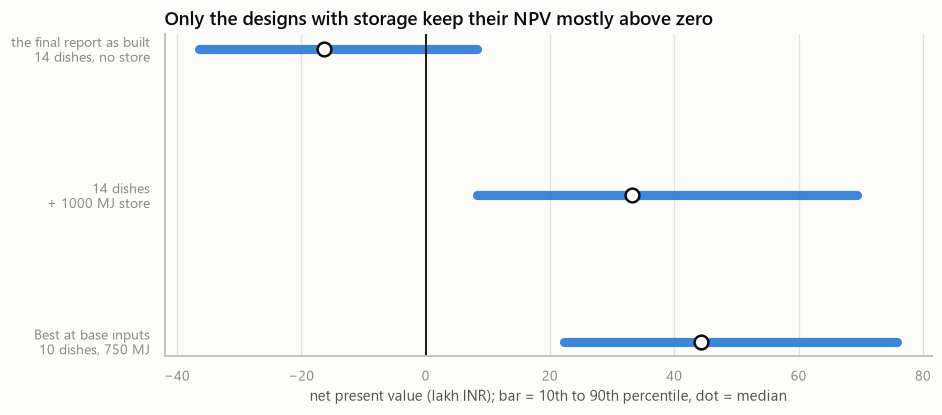

In [6]:
cands = {
    "the final report as built\n14 dishes, no store": (14, 0.0),
    "14 dishes\n+ 1000 MJ store": (14, 1000.0),
    f"Best at base inputs\n{int(best.n_dishes)} dishes, {best.storage_mj:.0f} MJ": (int(best.n_dishes), float(best.storage_mj)),
}
mc = {name: monte_carlo(ev, n, s, n=2000, seed=11) for name, (n, s) in cands.items()}
summary = pd.DataFrame({
    name.replace("\n", " "): {
        "NPV P10 (lakh)": d.npv_inr.quantile(.10) / LAKH, "NPV P50 (lakh)": d.npv_inr.median() / LAKH,
        "NPV P90 (lakh)": d.npv_inr.quantile(.90) / LAKH, "P(NPV < 0)": (d.npv_inr < 0).mean(),
        "solar share P50": d.solar_fraction.median(), "LCOH P50 (INR/MJ)": d.lcoh_inr_per_mj.median(),
        "P(solar heat cheaper than LPG)": (d.lcoh_inr_per_mj < d.lpg_inr_per_mj).mean(),
    } for name, d in mc.items()
}).T
display(summary.round(2))

fig, ax = plt.subplots(figsize=(9, 3.8))
for i, (name, d) in enumerate(list(mc.items())[::-1]):
    lo, md_, hi = (d.npv_inr.quantile(q) / LAKH for q in (0.10, 0.5, 0.90))
    ax.plot([lo, hi], [i, i], color=SERIES[0], linewidth=6, solid_capstyle="round", alpha=0.9)
    ax.plot([md_], [i], marker="o", markersize=9, color=SURFACE, markeredgecolor=INK["primary"], markeredgewidth=1.6, zorder=5)
ax.axvline(0, color=INK["primary"], linewidth=1.2)
ax.set_yticks(range(len(mc)), [n for n in list(mc)[::-1]], fontsize=9)
ax.set_xlabel("net present value (lakh INR); bar = 10th to 90th percentile, dot = median")
ax.grid(axis="y", visible=False)
ax.set_title("Only the designs with storage keep their NPV mostly above zero")
save(fig, FIG / "econ_mc_npv.png")
plt.show()

## 6: Which inputs drive the answer? Sobol sensitivity

Variance-based indices of the NPV for the 14-dish design with a 1000 MJ store (64 base samples, 1536 model runs). The total index (ST) is the share of the output variance an input is responsible for, alone or through interactions with others.

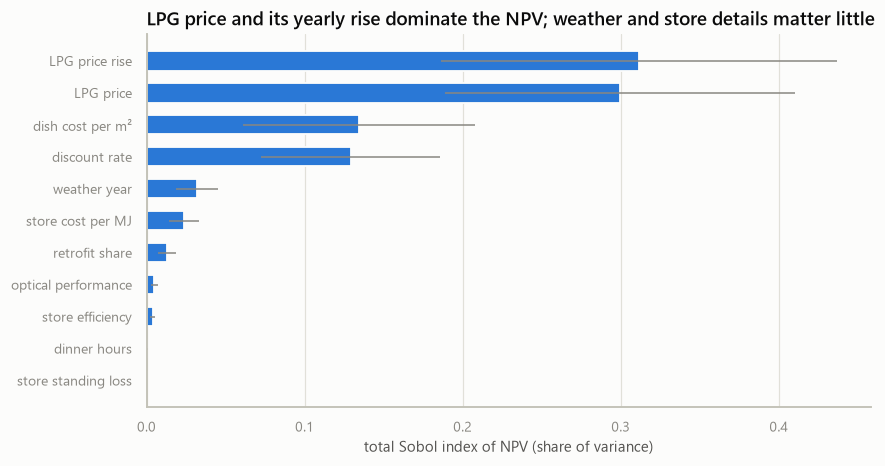

,S1,S1_conf,ST,ST_conf
lpg_escalation,0.274,0.176,0.311,0.125
lpg_price_inr,0.296,0.178,0.299,0.111
dish_cost_per_m2_inr,0.066,0.114,0.134,0.073
discount_rate,0.103,0.115,0.129,0.057
weather_year,0.035,0.050,0.032,0.013
storage_cost_per_mj_inr,0.006,0.052,0.024,0.009
retrofit_fraction,0.043,0.036,0.013,0.006
optical_multiplier,-0.000,0.020,0.005,0.002
storage_efficiency,0.010,0.018,0.004,0.002
dinner_shift_h,0.000,0.008,0.000,0.000


In [7]:
so = sobol_indices(ev, 14, 1000.0, "npv_inr", n_base=64, seed=5).sort_values("ST")
labels = {
    "weather_year": "weather year", "optical_multiplier": "optical performance", "dinner_shift_h": "dinner hours",
    "storage_efficiency": "store efficiency", "standing_loss_per_hour": "store standing loss", "lpg_price_inr": "LPG price",
    "lpg_escalation": "LPG price rise", "dish_cost_per_m2_inr": "dish cost per m²", "retrofit_fraction": "retrofit share",
    "storage_cost_per_mj_inr": "store cost per MJ", "discount_rate": "discount rate",
}
fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.barh([labels[k] for k in so.index], so.ST, color=SERIES[0], height=0.6, edgecolor=SURFACE, linewidth=1.2, xerr=so.ST_conf, error_kw={"ecolor": INK["muted"], "elinewidth": 1})
ax.set_xlabel("total Sobol index of NPV (share of variance)")
ax.grid(axis="y", visible=False)
ax.set_title("LPG price and its yearly rise dominate the NPV; weather and store details matter little")
save(fig, FIG / "econ_sobol.png")
plt.show()
display(so.sort_values("ST", ascending=False).round(3))

## What this notebook establishes, and what it does not

* **Established:** the economics of the final report's design change sign once the retrofit it lists but omits is added and no storage is assumed; with a store of about 1000 MJ the 14-dish design has a positive median NPV and pays back. The chart and table above give the percentiles.
* **Established:** weather variability between real years is modest (about plus or minus 5 % in beam energy); the economic outcome is far more sensitive to the LPG price (its level and its yearly rise together account for about 60 % of the NPV variance), then to the dish cost and the discount rate (about 13 % each), than to the weather year (3 %) or the store's efficiency and losses (under 1 %).
* **Reading the Monte Carlo medians:** they sit above the base-case values (for example 33 lakh against 11 lakh for the 14-dish design with a store) because the drawn LPG price rise averages about 3 % a year, whereas the base case, like the final report, assumes none. The base-case table in section 2 is the like-for-like comparison with the final report.
* **Not established:** the store cost (a placeholder; the whole storage case rests on it), the store's efficiencies and the meal hours (judgement ranges), future LPG prices, and the accuracy of PVGIS beam irradiance in the monsoon. Replacing the placeholder store cost with a supplier quotation is the most valuable next input.
* **Caveat on "best":** the best design is optimal at the base inputs and one weather year type; under the uncertain inputs a different design may be more robust, which is why the percentiles are shown next to it.